# 01 · Data exploration

Goal: understand the dataset before modelling — size, label distribution, text
length, a few examples, anything odd (duplicates, empty texts, imbalance).
Findings → slide 1 and the decisions log in `README.md`.

In [28]:
# Setup: make the course code (part1) and our code (src) importable.
# Run notebooks from this folder (JupyterLab / VS Code do this by default).
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve().parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data

## Load

In [30]:
pairs, outcome_space, stats = data.load_pairs(label_mode="fine")
print(stats)
df = pd.DataFrame(pairs, columns=["text", "label"])
df["label_name"] = df["label"].map(outcome_space.name)
len(df), outcome_space

{'label_mode': 'fine', 'min_raters': 2, 'comments_with_label': 54263, 'kept': 45446, 'dropped_multilabel': 8817}


(45446,
 NamedClasses(('admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral')))

### Vocab size

In [40]:
vocab_size = len(set(" ".join(df["text"]).split()))
min_frequency = df["text"].str.split(expand=True).stack().value_counts().min()
print(f"Vocabulary size: {vocab_size}")
print(f"Minimum frequency: {min_frequency}")

Vocabulary size: 58800
Minimum frequency: 1


## Label distribution
Is it balanced? If not, accuracy alone may be misleading (consider macro-F1).

,n,share
label_name,,
neutral,16021,0.352528
admiration,3384,0.074462
gratitude,2378,0.052326
approval,2367,0.052084
amusement,2046,0.045020
annoyance,1809,0.039805
disapproval,1809,0.039805
love,1760,0.038727
curiosity,1729,0.038045


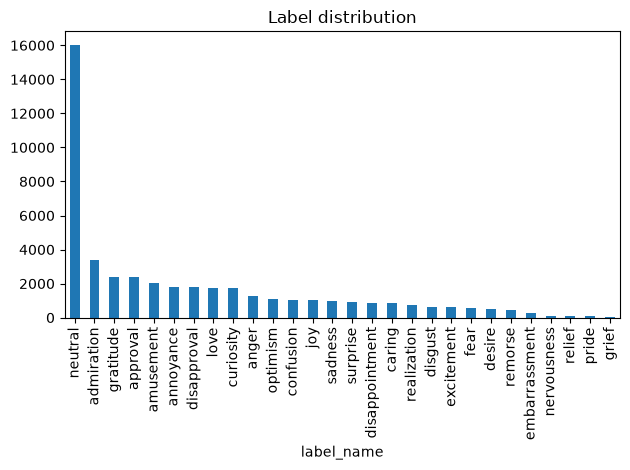

In [32]:
counts = df["label_name"].value_counts()
ax = counts.plot.bar(title="Label distribution")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "label_distribution.png", dpi=200)
counts.to_frame("n").assign(share=lambda t: t.n / t.n.sum())

## Text length

In [33]:
df["n_words"] = df["text"].str.split().str.len()
df["n_words"].describe()

count    45446.000000
mean        12.598733
std          6.718282
min          1.000000
25%          7.000000
50%         12.000000
75%         18.000000
max         32.000000
Name: n_words, dtype: float64

## Examples per label

In [34]:
for name, group in df.groupby("label_name"):
    print(f"--- {name}")
    for text in group["text"].sample(2, random_state=config.SEED):
        print("  ", text[:200])

--- admiration
   Sick burn. I like it.
   Awesome map!
--- amusement
   This is actually so funny, this is something id expect from Australian sports media since we're shit at broadcasting but lmao
   Ah, tis the coder life. Be glad you didn't accidentally wipe a database or something, haha.
--- anger
   I hate deer. Damn big assed rats
   yeah violence shouldn't be your goto first option, but the people who pretend words are meaningless sounds are stupid idiots
--- annoyance
   It's the wisdom of the fool.
   I honestly do not know. Chastise them for their hardness of heart and presumptiveness I suppose. I guess that is what [NAME] would do.
--- approval
   Ditto!!!
   They are very heavily scripted which is why it can be borderline unethical.
--- caring
   my 3.5mm jack came with my iphone se and I can literally never lose it as long as I have my phone.
   sounds good, take care & stay safe loves💕
--- confusion
   I wasn’t considering potatoes in the discussion or else it’s a clear 